last modified date : 2026.11

# 양자화 오차 분석과 품질 검증 실습

## 오늘 확인할 문제

**4비트 모델의 평균 점수가 같아도 교체 결정을 보류해야 하는 경우는 무엇입니까?**

중요 질문의 실제 답변과 자동 채점 결과를 대조해 4비트 양자화 모델의 교체 여부를 판단하고 근거를 기록합니다. D38에서 비교한 정밀도별 품질·속도·메모리와 D39의 NF4 학습을 짧게 복습한 뒤 같은 비트에서도 스케일과 입력에 따라 오차가 달라지는 이유와 자동 점수가 놓치는 답을 확인합니다. D53에서 실행한 챗봇의 모델을 교체한다고 가정하고 중요한 질문을 먼저 정해 검토합니다.

먼저 판단과 이유를 두 문장으로 적습니다. 실습 뒤에는 자신의 결과로 판단을 다시 설명합니다.

**학습목표**

- [목표 1] 스케일·그룹과 입력을 바꾸어 가중치 오차와 출력 오차의 차이를 그림으로 설명할 수 있다.
- [목표 2] 같은 조건의 원본·4비트 결과에서 자동 채점과 실제 답을 대조해 오판을 찾을 수 있다.
- [목표 3] 중요 질문의 답과 자원 측정을 근거로 교체 판단을 기록하고 다음 차시에 쓸 파일을 보관할 수 있다.

### 앞선 품질 비교 리마인드

D38에서 비교한 메모리·속도·태스크별 품질을 다시 떠올립니다. D38의 선택 실습을 하지 않았어도 오늘 제공하는 측정 코드로 확인할 수 있습니다.

| 이미 다룬 내용 | 오늘 확인할 질문 |
|---|---|
| 4비트 로드와 NF4 설정 | 메모리만 줄었습니까, 실제 답도 달라졌습니까? |
| 정밀도별 품질·속도 비교 | 평균이 같을 때 어떤 문항을 다시 읽어야 합니까? |
| fp16·bf16과 계산 형식 | 비교할 때 계산 형식과 GPU를 같게 고정했습니까? |

오늘 새로 수행할 일은 스케일·입력에 따른 출력 오차 분석, 채점기 검산, 중요 질문의 원문 검토입니다. Step 5에서는 원본과 NF4 두 행을 짧게 비교하고 8비트 추가 비교는 Step 7에서 선택합니다.

오늘 새로 남기는 판단 기록은 `d54_decision.json`이며 기존 결과 파일을 대체하지 않습니다. 하네스와 결과의 이름·키는 D55\~57과 맞춥니다.

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 앞선 품질 비교 복습·평가 계획 | 45분 | 이론 1장·4.4절, Step 0\~1 |
| 스케일·그룹과 출력 오차 | 95분 | 이론 2\~3장, Step 2\~3 |
| 채점 검산·원본과 4비트 비교 | 115분 | 이론 4장·6.1\~6.3절, Step 4\~5 |
| 중요 답 검토·교체 근거·인계 | 105분 | 이론 5장·6.4\~6.6절, Step 6·8 |

필수 학습은 360분입니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함해 480분으로 계획합니다. 이론과 코드는 표의 순서로 함께 진행합니다. 선택 실습은 필수 수행에 추가하지 않으며 시간은 실측값이 아닙니다.

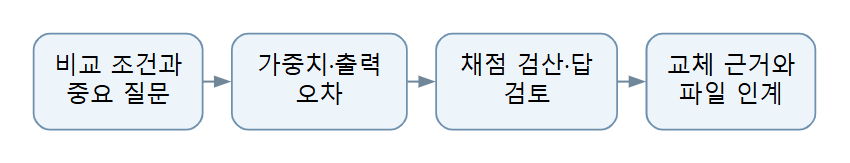

**그림.** 비교 조건과 중요 질문 → 가중치·출력 오차 → 채점 검산·답 검토 → 교체 근거와 파일 인계의 관계를 나타낸 개념도입니다. 실측 성능값이나 실제 실행 화면이 아닙니다.

### 먼저 읽을 용어

| 용어 | 이 노트에서의 뜻 |
|---|---|
| 스케일 | 정수 단계와 실제 값 사이의 환산 값 |
| 그룹 | 스케일 하나를 공유하도록 묶은 값들 |
| 활성값 | 입력을 처리하며 층 안에서 계산되는 값 |
| 회귀 문항(flip 중 맞→틀) | 기준 모델이 맞혔지만 후보 모델이 틀린 질문 |
| 하네스 | 같은 조건으로 모델을 실행하고 평가하는 공통 코드 |

### 실행 환경

Colab Pro+의 GPU 런타임을 사용합니다. 배정된 GPU 이름을 기록하며 L4·A100에서도 원본 비교는 fp16으로 고정합니다. 작은 행렬 실험과 평가 함수 검산은 GPU 없이도 가능하고 실제 모델 측정은 Step 5에서 GPU가 필요합니다.

| 항목 | 내용 |
|---|---|
| 모델 | Qwen2.5-1.5B-Instruct, 원본 fp16과 NF4를 차례로 로드 |
| 추가 비교 | Step 7의 int8은 선택이며 큰 모델을 추가로 받지 않음 |
| 필요한 키 | 없음. 공개 모델 사용 |
| 남길 파일 | `bench_harness.py`, `d54_results.json`, `d54_decision.json` |
| 다음 차시 | D55는 앞의 두 파일을 사용하며 조건이 달라지면 재측정 |

설치·모델 다운로드·실제 측정 시간은 배정된 GPU와 네트워크에 따라 달라집니다. 원본·NF4 두 번의 측정은 D38의 품질 비교를 복습하면서 공통 평가 기록을 만드는 데 사용합니다. 기다리는 동안 새 모델을 더 받지 않고 질문·채점 규칙·중요 질문의 근거를 검토합니다.

### Step 0. 환경 준비

In [1]:
# 버전을 고정합니다. 0.x 버전인 bitsandbytes 는 마이너 버전까지 묶습니다
!pip install -q "transformers>=5.17,<6" "accelerate>=1.15,<2" "bitsandbytes>=0.50,<0.51"
# 의존성 충돌이 보고되면 [런타임] - [세션 다시 시작] 후 이 셀 아래부터 다시 실행하세요

In [2]:
import gc, json, os, re, time
from collections import Counter
from importlib.metadata import version, PackageNotFoundError

import torch


def pkgver(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return "미설치"


print("[설치된 버전]", {dd: pkgver(dd) for dd in ["torch", "transformers", "accelerate", "bitsandbytes"]})

HAS_GPU = torch.cuda.is_available()
# is_bf16_supported() 는 에뮬레이션까지 세므로 세대(8 이상)로 판단합니다
NATIVE_BF16 = HAS_GPU and torch.cuda.get_device_capability(0)[0] >= 8
if HAS_GPU:
    prop, CAP = torch.cuda.get_device_properties(0), torch.cuda.get_device_capability(0)
    print(f"GPU : {prop.name}, {prop.total_memory / 1e9:.1f} GB, compute capability {CAP[0]}.{CAP[1]}")
    print(f"is_bf16_supported() 기본값 {torch.cuda.is_bf16_supported()}, "
          f"에뮬레이션 제외 {torch.cuda.is_bf16_supported(including_emulation=False)}")
else:
    print("GPU 가 없습니다. Step 1~3 은 CPU 에서 실행되고 Step 4 부터는 GPU 런타임이 필요합니다")
DTYPE16 = torch.float16  # AWQ와 같은 기준으로 비교합니다
print(f"16비트 기준 형식 : {DTYPE16}")

[설치된 버전] {'torch': '2.11.0+cu130', 'transformers': '5.22.0', 'accelerate': '1.15.0', 'bitsandbytes': '0.50.2'}
GPU : Tesla T4, 15.6 GB, compute capability 7.5
is_bf16_supported() 기본값 True, 에뮬레이션 제외 False
16비트 기준 형식 : torch.float16


GPU 지원 여부는 실제 출력에서 읽습니다. D39에서 다룬 bf16 판별은 여기서 재강의하지 않습니다. 이 실습은 같은 fp16 기준으로 비교합니다.

### Step 1. 앞선 비교 복습과 예측

모델을 실행하기 전에 세 문장으로 예상합니다. 원본과 NF4 중 메모리가 더 적을 쪽, 더 빠를 쪽, 중요 질문에서 틀릴 가능성을 어떻게 확인할지 적습니다. D38의 실측을 기억하지 못해도 예상과 이유를 쓰고 Step 5에서 확인합니다.

형식별 범위 출력은 아래의 복습 참고에만 둡니다. 본 활동에서는 다시 실행하지 않습니다.

<details>
<summary>복습 참고: fp16·bf16의 범위 출력 코드</summary>

```python
FORMATS = [("fp32", torch.float32), ("fp16", torch.float16), ("bf16", torch.bfloat16),
           ("FP8 E4M3", torch.float8_e4m3fn), ("FP8 E5M2", torch.float8_e5m2)]

print(f"{'형식':<10} {'비트':>4} {'가장 큰 수':>14} {'1 바로 다음 수':>16} {'가장 작은 정규 수':>18}")
for name, dt in FORMATS:
    fi = torch.finfo(dt)
    print(f"{name:<10} {fi.bits:>4} {fi.max:>14.6g} {1 + fi.eps:>16.7g} {fi.tiny:>18.3g}")
```

```python
def cast(value, dtype):   # 32비트 값을 다른 형식에 담았다가 다시 꺼냅니다
    return torch.tensor(value, dtype=torch.float32).to(dtype).float().item()


for title, v in [("[오버플로] 70,000", 70000.0), ("[언더플로] 0.00000001", 1e-8)]:
    print(f"{title} 을 담으면  fp16 : {cast(v, torch.float16)}  bf16 : {cast(v, torch.bfloat16)}")

one16, one_b = torch.tensor(1.0, dtype=torch.float16), torch.tensor(1.0, dtype=torch.bfloat16)
print("[정밀도 손실] 1 에 작은 수를 더하면")
print(f"  fp16 : 1 + 0.0001 = {(one16 + torch.tensor(1e-4, dtype=torch.float16)).item()}")
print(f"  bf16 : 1 + 0.001  = {(one_b + torch.tensor(1e-3, dtype=torch.bfloat16)).item()}")
```

**세 줄을 이론 노트와 맞춰 읽습니다.**

- **오버플로** : fp16은 `inf`가 되고 bf16은 70,144처럼 가까운 값으로 담깁니다. bf16의 범위가 fp32와 같아서입니다  
- **언더플로** : fp16은 0이 되고 bf16은 담깁니다. 이 차이가 5.2절의 손실 스케일링이 fp16에만 필요한 까닭입니다  
- **정밀도 손실** : 둘 다 1이 남습니다. 16비트 사본만으로 학습하면 작은 갱신이 이렇게 사라집니다. 앞선 D39 실습에서 다룬 학습 설정과 연결합니다

</details>

### Step 2. 스케일과 영점 직접 구현

양자화의 반올림 오차를 직접 계산합니다. 8비트 예제에서 스케일을 확인한 뒤, 큰 값 하나가 작은 값의 구분에 미치는 영향을 봅니다. D38의 로드 설정이 숫자에 어떤 변화를 주는지 설명하기 위한 작은 실험입니다.

In [ ]:
# 실습 : 빈칸을 채워 대칭 양자화 함수를 완성하세요

def quantize_absmax(x, bits=8):
    """반환값 : (정수 텐서 q, 스케일 scale). 역양자화는 q / scale"""
    qmax = 2 ** (bits - 1) - 1          # 8비트면 127, 4비트면 7
    ### START CODE HERE ### (가장 큰 절댓값으로 스케일 scale 계산 1줄)
    # 1) qmax 를 x 의 가장 큰 절댓값으로 나눈 값. 모든 값이 0 인 텐서도 0 으로 나누지 않게 clamp(min=1e-12) 로 막습니다
    scale = qmax / x.abs().max().clamp(min=1e-12)
    ### END CODE HERE ###
    if scale is None:
        return None
    q = torch.round(x * scale).clamp(-qmax, qmax)
    return q, scale

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
scale = qmax / x.abs().max().clamp(min=1e-12)
```

`clamp(min=1e-12)`는 값이 전부 0인 행렬이 들어왔을 때를 막습니다. 실제 모델에는 0으로만 채워진 행이 드물게 있고 그때 나눗셈이 `inf`를 만들면 오류 없이 결과만 망가집니다.

</details>

In [4]:
x = torch.tensor([1.2, -0.5, -4.3, 1.2, -3.1, 0.8, 2.4, 5.4])

res = quantize_absmax(x, 8)
if res is None:
    print("quantize_absmax 의 빈칸이 아직 비어 있습니다. 채우고 실습 셀부터 다시 실행하세요")
else:
    q, scale = res
    back = q / scale
    print("스케일    :", round(float(scale), 2))
    print("정수      :", q.int().tolist())
    print("역양자화  :", [round(v, 3) for v in back.tolist()])
    print(f"최대 오차 : {float((back - x).abs().max()):.4f}  (양자화 간격의 절반 {0.5 / float(scale):.4f})")

스케일    : 23.52
정수      : [28, -12, -101, 28, -73, 19, 56, 127]
역양자화  : [1.191, -0.51, -4.294, 1.191, -3.104, 0.808, 2.381, 5.4]
최대 오차 : 0.0189  (양자화 간격의 절반 0.0213)


정수가 `[28, -12, -101, 28, -73, 19, 56, 127]`로 출력되면 이론 노트 2.1절과 같습니다. 최대 오차가 양자화 간격의 절반보다 작은지도 확인합니다.

같은 여덟 값 끝에 60을 하나 붙여 이론 노트 3.1절의 일을 재현합니다.

In [5]:
x_out = torch.cat([x, torch.tensor([60.0])])

for bits in (8, 4):
    res = quantize_absmax(x_out, bits)
    if res is None:
        print("quantize_absmax 의 빈칸을 먼저 채우세요")
        break
    q, scale = res
    back = q / scale
    err = float((back[:-1] - x_out[:-1]).abs().max())            # 60 을 뺀 여덟 값의 오차
    zeros = int((q[:-1] == 0).sum())
    print(f"{bits}비트 : 정수 {q.int().tolist()}  여덟 값의 최대 오차 {err:.2f}, 0이 된 값 {zeros}개")

8비트 : 정수 [3, -1, -9, 3, -7, 2, 5, 11, 127]  여덟 값의 최대 오차 0.22, 0이 된 값 0개
4비트 : 정수 [0, 0, -1, 0, 0, 0, 0, 1, 7]  여덟 값의 최대 오차 4.27, 0이 된 값 6개


8비트에서는 여덟 값의 최대 오차가 0.02에서 0.22로 커지고 4비트에서는 여섯 값이 0이 됩니다. 큰 값 하나가 스케일을 정하면 양자화 간격이 넓어져 나머지 값의 차이가 반올림으로 사라집니다.

이번에는 0에서 10 사이에만 있는 값을 대칭과 비대칭으로 양자화해 봅니다. 이론 노트 2.2절의 영점입니다.

In [6]:
def quantize_zeropoint(x, bits=8):
    """비대칭 : 가장 작은 값이 최솟값 레벨, 가장 큰 값이 최댓값 레벨에 옵니다"""
    qmin, qmax = -(2 ** (bits - 1)), 2 ** (bits - 1) - 1      # 8비트면 -128 ~ 127
    lo, hi = x.min(), x.max()
    scale = (qmax - qmin) / (hi - lo).clamp(min=1e-12)
    zero = torch.round(qmin - lo * scale)                       # 실수 0 이 오는 레벨 = 영점
    q = torch.round(x * scale + zero).clamp(qmin, qmax)
    return q, scale, zero


skew = torch.rand(10000, generator=torch.Generator().manual_seed(1)) * 10   # 0 ~ 10 사이만

res = quantize_absmax(skew, 8)
if res is None:
    print("Step 2 실습 셀의 빈칸을 먼저 채우세요")
else:
    q_s, s_s = res
    err_s = (q_s / s_s - skew).abs()
    q_a, s_a, z_a = quantize_zeropoint(skew, 8)
    err_a = ((q_a - z_a) / s_a - skew).abs()
    print(f"{'방식':<8} {'쓴 레벨 수':>8} {'평균 오차':>10} {'최대 오차':>10}")
    for name, qq, e in [("대칭", q_s, err_s), ("비대칭", q_a, err_a)]:
        print(f"{name:<8} {qq.unique().numel():>8} {float(e.mean()):>10.4f} {float(e.max()):>10.4f}")
    print(f"\n영점 : 레벨 {int(z_a)} 에 실수 0 이 옵니다")

방식         쓴 레벨 수      평균 오차      최대 오차
대칭            128     0.0199     0.0394
비대칭           256     0.0097     0.0196

영점 : 레벨 -128 에 실수 0 이 옵니다


대칭·비대칭의 오차를 출력값으로 비교합니다. 값의 분포와 영점의 반올림에 따라 결과가 달라지므로, 레벨 수가 늘면 실제 오차가 언제나 정확히 절반이 된다고 단정하지 않습니다.

### Step 3. 같은 4비트의 가중치·출력 오차

스케일을 전체 행렬·행·8개씩 묶은 그룹에 각각 둡니다. 가중치의 오차 그림을 예측한 뒤 실행하고 같은 가중치에 두 입력을 곱했을 때 출력 오차를 비교합니다.

행렬과 입력은 이 코드가 만든 교육용 값입니다. NF4·GPTQ·AWQ의 실제 구현이나 모델 측정값으로 해석하지 않습니다. 스케일은 32비트로 저장한다고 가정합니다.

Step 2의 `scale`은 실제 값을 정수로 옮길 때 곱하는 배율입니다. 아래의 `step`은 정수를 다시 실제 값으로 복원할 때 곱하는 간격이며 두 값은 서로 역수입니다. 아래 코드는 복원한 값의 차이를 그림으로 비교합니다.

unit          W MSE     Y left    Y right   scales   bytes*
tensor     0.006810   0.690683   0.784133        1      132
row        0.000670   0.032967   0.084464        8      160
group8     0.000127   0.015838   0.005516       32      256
bytes*: 4비트 가중치와 32비트 스케일을 가정한 계산값이며 NumPy 배열의 실제 크기가 아닙니다.


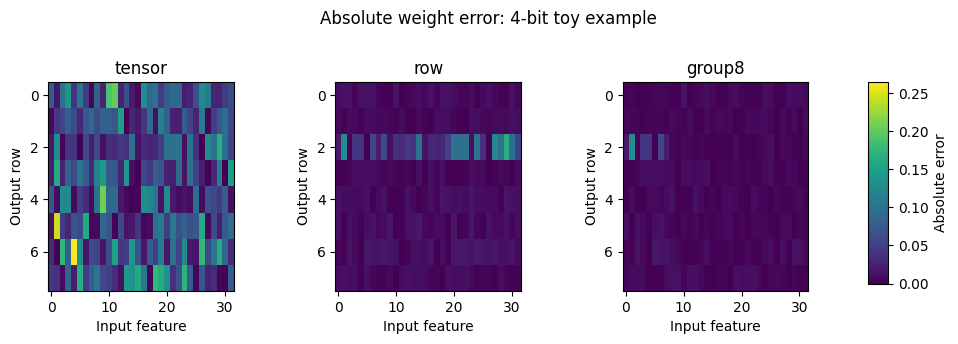

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def grouped_roundtrip(weight, group=None, bits=4):
    """교육용 대칭 정수 양자화. NF4나 GPTQ·AWQ의 구현이 아닙니다."""
    a = np.asarray(weight, dtype=np.float64)
    if a.ndim != 2 or not a.size or not np.isfinite(a).all():
        raise ValueError("유한한 값이 있는 비어 있지 않은 2차원 행렬이 필요합니다.")
    if not isinstance(bits, int) or bits < 2:
        raise ValueError("bits는 2 이상의 정수로 지정합니다.")
    if group is None:
        blocks = a.reshape(1, 1, -1)
    else:
        if not isinstance(group, int) or group <= 0 or a.shape[1] % group:
            raise ValueError("그룹 크기는 열 수를 나누는 양의 정수여야 합니다.")
        blocks = a.reshape(a.shape[0], -1, group)
    qmax = 2 ** (bits - 1) - 1
    # 4비트일 때 -7~7을 쓰는 교육용 대칭 범위입니다.
    step = np.maximum(np.max(np.abs(blocks), axis=-1, keepdims=True) / qmax, 1e-12)
    codes = np.clip(np.rint(blocks / step), -qmax, qmax)
    restored = (codes * step).reshape(a.shape)
    return restored, int(step.size)

rng = np.random.default_rng(54)
W_demo = rng.normal(0, .08, size=(8, 32))
W_demo[2, 5] = 4.5  # 큰 값 하나를 의도적으로 넣은 교육용 행렬입니다.
X_left = rng.normal(size=(12, 32)); X_left[:, :8] *= 3
X_right = rng.normal(size=(12, 32)); X_right[:, 24:] *= 3
variants = {"tensor": None, "row": 32, "group8": 8}
toy_results = []
for name, group in variants.items():
    restored, scales = grouped_roundtrip(W_demo, group)
    toy_results.append({"unit": name, "weight_mse": float(np.mean((W_demo-restored)**2)),
        "output_mse_left": float(np.mean((X_left@W_demo.T-X_left@restored.T)**2)),
        "output_mse_right": float(np.mean((X_right@W_demo.T-X_right@restored.T)**2)),
        "scales": scales,
        "illustrative_bytes": W_demo.size*.5+scales*4})
print(f"{'unit':<8} {'W MSE':>10} {'Y left':>10} {'Y right':>10} {'scales':>8} {'bytes*':>8}")
for row in toy_results:
    print(f"{row['unit']:<8} {row['weight_mse']:>10.6f} {row['output_mse_left']:>10.6f} "
          f"{row['output_mse_right']:>10.6f} {row['scales']:>8} {row['illustrative_bytes']:>8.0f}")
print("bytes*: 4비트 가중치와 32비트 스케일을 가정한 계산값이며 NumPy 배열의 실제 크기가 아닙니다.")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
vmax = max(float(np.max(np.abs(grouped_roundtrip(W_demo, group)[0]-W_demo))) for group in variants.values())
for ax, (name, group) in zip(axes, variants.items()):
    restored, _ = grouped_roundtrip(W_demo, group)
    err = np.abs(restored-W_demo)
    img = ax.imshow(err, aspect="auto", vmin=0, vmax=vmax)
    ax.set(title=name, xlabel="Input feature", ylabel="Output row")
fig.suptitle("Absolute weight error: 4-bit toy example", fontsize=12)
fig.subplots_adjust(left=.06, right=.82, bottom=.2, top=.78, wspace=.55)
cax = fig.add_axes([.88, .22, .02, .56])
fig.colorbar(img, cax=cax, label="Absolute error")
fig.savefig("d54_group_error.png", dpi=85); plt.show()


**[목표 1] 그림과 표를 함께 읽습니다.**

1. 큰 값 하나의 영향이 전체·행·그룹 중 어디까지 퍼졌는지 그림에서 찾습니다.
2. 같은 복원 가중치에서 `output_mse_left`와 `output_mse_right`가 다른 이유를 입력과 연결합니다.
3. `scales`가 늘 때 가정한 저장 비용이 어떻게 달라지는지 설명합니다.

그룹 8을 4나 16으로 한 번 바꾸어 예측을 확인합니다. 이 변경은 교육용 행렬에만 적용됩니다. bitsandbytes NF4의 그룹 크기를 바꾸는 코드가 아닙니다.

### Step 4. 공통 평가 코드와 채점기 검산

오늘은 공통 평가 코드(`bench_harness.py`)에서 숫자·분류·형식 채점기를 검산하고 맞→틀 회귀 문항을 확인하는 함수를 점검합니다. 하네스는 같은 질문과 설정으로 모델을 실행하고 기록하는 코드가며 D38의 정밀도별 표를 재현하는 기본 코드는 그대로 제공합니다.

아래 셀을 위에서부터 실행하면 `bench_harness.py`가 만들어집니다. D55\~57도 읽으므로 함수·질문·키는 유지합니다. 모델 비교 전에 채점기의 기대 결과를 확인합니다.

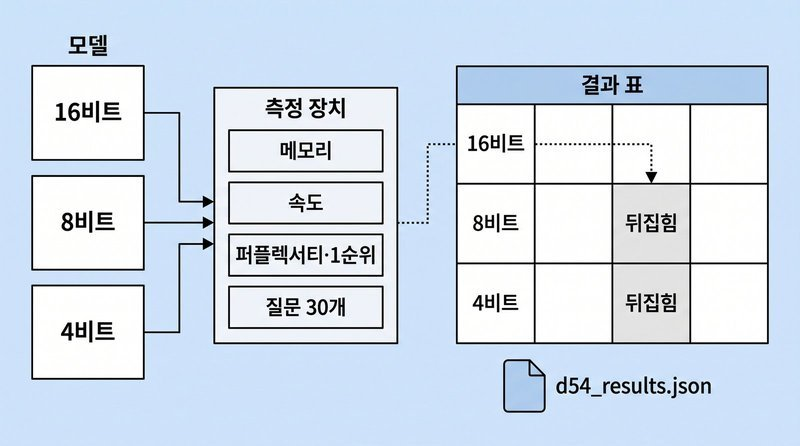

*모든 정밀도를 같은 하네스로 측정하고 16비트를 기준선으로 flip을 셉니다.*

In [ ]:
%%writefile bench_harness.py
"""54일차 벤치마크 하네스. 55~57일차가 import 해서 씁니다"""
import gc, json, math, os, re, time
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

HAS_GPU = torch.cuda.is_available()
# Step 0 과 같은 규칙 : bf16 은 compute capability 8 이상
DTYPE16 = torch.float16  # 같은 fp16 기준선으로 정밀도 효과를 비교합니다

# 모델 이름은 환경 변수가 있으면 거기서 읽습니다. 서빙 프로젝트에서 들인 습관입니다
MODEL_ID = os.environ.get("D54_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
# 측정할 때는 GPU 0번에 고정합니다. "auto" 로 두면 메모리가 모자랄 때 조용히 CPU 로 내려가
# 속도 측정값이 엉뚱해집니다(로컬 GPU 배포 노트 4.2절의 로드 방식)
DEVICE_MAP = {"": 0} if HAS_GPU else "cpu"

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

TEXT_KO = """한결물산 근무 규정 (실습용으로 지어낸 문서입니다)

제1조 (목적) 이 규정은 한결물산 임직원의 근무 시간, 재택근무, 휴가, 출장, 정보 보안에 관한 기준을 정한다.
제2조 (근무 시간) 기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다. 시차 출퇴근제를 신청한 직원은 오전 8시에서 10시 사이에 출근할 수 있다.
제3조 (재택근무) 재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.
제4조 (연차 휴가) 1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다.
제5조 (출장비) 국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.
제6조 (정보 보안) 회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
제7조 (경조 휴가) 본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다.
제8조 (교육 지원) 직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다.
제9조 (장비 대여) 업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 빌린 장비는 퇴사 전에 반납한다.
제10조 (법인카드) 법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다.
제11조 (회의) 정기 회의는 매주 월요일 오전 10시에 연다. 회의록은 회의가 끝난 날 안에 공유한다.
제12조 (개정) 이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."""

TEXT_EN = """Hangyeol Trading Work Rules (a document made up for this exercise)

Article 1 (Purpose) These rules set the standards for working hours, remote work, leave, business trips, and information security for employees of Hangyeol Trading.
Article 2 (Working hours) Regular working hours are from 9 a.m. to 6 p.m., and the lunch break is one hour from noon to 1 p.m. Employees who have applied for flexible hours may start work between 8 a.m. and 10 a.m.
Article 3 (Remote work) Employees may apply for remote work up to two days a week. Applications are made to the team leader by 3 p.m. on the day before. New employees may apply for remote work only after three months from joining.
Article 4 (Annual leave) Employees who have worked for one year or more receive 15 days of annual leave a year. Annual leave may be divided into half-day units. To take three or more consecutive days, apply at least two weeks in advance.
Article 5 (Travel expenses) For domestic business trips, accommodation is paid at actual cost up to 100,000 won per night. Meals are paid at a flat rate of 30,000 won per day. Settlement is requested with receipts within five days after the trip ends.
Article 6 (Information security) Company laptops must always be screen-locked when the employee leaves the desk. Files containing customer information are not sent by external email. An employee who learns of a security incident reports it to the security team within one hour.
Article 7 (Family event leave) Employees receive five days of leave for their own wedding and one day for a child's wedding. Five days are given when a parent dies.
Article 8 (Training support) External training related to the job is supported up to 1,000,000 won a year. Employees who complete training submit a report within two weeks.
Article 9 (Equipment rental) Work monitors and keyboards can be borrowed from the general affairs team. Borrowed equipment is returned before leaving the company.
Article 10 (Corporate card) The corporate card is used only for business purposes. Any single payment over 500,000 won requires prior approval from the finance team.
Article 11 (Meetings) The regular meeting is held every Monday at 10 a.m. Minutes are shared on the same day the meeting ends.
Article 12 (Amendment) When these rules change, all employees are notified at least two weeks before they take effect."""

TEXTS = {"ko": TEXT_KO, "en": TEXT_EN}

Writing bench_harness.py


In [ ]:
%%writefile -a bench_harness.py


LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]

Appending to bench_harness.py


In [ ]:
%%writefile -a bench_harness.py


def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.fullmatch(r"\s*(\{.*\})\s*", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False

Appending to bench_harness.py


In [ ]:
%%writefile -a bench_harness.py


def make_bnb_config(precision):
    """정밀도 이름을 양자화 설정으로 바꿉니다. 인자는 기본값에 맡기지 않고 전부 적습니다"""
    if precision == "16bit":
        return None
    if precision == "int8":
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
    if precision == "int8_t0":                    # 부록 실습 D : 이상치 분리를 끈 8비트
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=0.0)
    if precision == "nf4":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_compute_dtype=DTYPE16, bnb_4bit_use_double_quant=True)
    if precision == "default4":                   # Step 6 : 한 줄짜리 설정
        return BitsAndBytesConfig(load_in_4bit=True)
    raise ValueError(f"모르는 정밀도 : {precision}")


def vram_gb(peak=False):
    """GPU 메모리(GB). GPU 가 없으면 None 을 반환합니다"""
    if not HAS_GPU:
        return None
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


def load_model(model_id, precision, pass_dtype=True):
    """모델을 로드해 딕셔너리 하나에 담아 반환합니다. 실패하면 예외 대신 error 를 담아 반환합니다"""
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    kwargs = {"device_map": DEVICE_MAP}
    if pass_dtype:
        kwargs["dtype"] = DTYPE16                 # torch_dtype= 은 폐기되었습니다
    qc = make_bnb_config(precision)
    if qc is not None:
        kwargs["quantization_config"] = qc
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return {"error": "GPU 메모리 부족", "precision": precision}
    except Exception as e:
        return {"error": f"{type(e).__name__}: {str(e)[:160]}", "precision": precision}
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return {"model_id": model_id, "precision": precision, "tok": tok, "model": model,
            "load_sec": time.time() - t0, "weights_gb": vram_gb(),
            "footprint_gb": model.get_memory_footprint() / 1e9}


def unload(h):
    """모델을 언로드하고 메모리가 실제로 줄었는지 수치로 보여 줍니다(모델 선택 실습의 방식)"""
    before = vram_gb()
    h["tok"] = h["model"] = None
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        after = vram_gb()
        print(f"  [언로드] GPU 메모리 {before:.2f} -> {after:.2f} GB")
        if before > 0.1 and after > before * 0.3:
            print("  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요")


def describe_layers(model):
    """층마다 어떤 형식으로 로드되었는지 셉니다. Qwen2 계열의 층 이름을 씁니다"""
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, nn.Linear) or "Linear" in type(m).__name__)
    q = model.model.layers[0].self_attn.q_proj
    info = {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}
    if hasattr(q, "compute_dtype"):
        info["4비트 계산 형식"] = str(q.compute_dtype)
        info["4비트 형식"] = getattr(q.weight, "quant_type", "-")
    return info

Appending to bench_harness.py


In [12]:
%%writefile -a bench_harness.py


@torch.no_grad()
def perplexity_top1(h, text, window=512, stride=256):
    """글 한 편의 퍼플렉서티와 위치마다의 1순위 예측을 측정합니다.

    윈도우를 stride 만큼 밀며 새로 들어온 토큰만 채점합니다(허깅페이스 문서의 방식).
    윈도우 크기와 stride 를 바꾸면 값이 바뀌므로 정밀도끼리 비교할 때는 고정합니다(이론 노트 6.2절).
    반환값 : (퍼플렉서티, 1순위 예측 텐서, 채점한 토큰 수)
    """
    tok, model = h["tok"], h["model"]
    ids = tok(text, return_tensors="pt")["input_ids"].to(model.device)
    n = ids.shape[1]
    nll_sum, count, preds, prev_end = 0.0, 0, [], 0
    for begin in range(0, n, stride):
        end = min(begin + window, n)
        x = ids[:, begin:end]
        logits = model(x).logits.float()          # 확률 계산은 32비트로 합니다
        k = min(end - prev_end, x.shape[1] - 1)    # 이번 윈도우에서 새로 채점할 토큰 수
        if k <= 0:                                # 토큰이 하나뿐인 윈도우는 채점할 것이 없습니다
            prev_end = end
            continue
        lg = logits[:, :-1][:, -k:]               # 위치 t 의 출력이 토큰 t+1 을 맞힙니다
        tgt = x[:, 1:][:, -k:]
        nll_sum += F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1),
                                   reduction="sum").item()
        count += tgt.numel()
        preds.append(lg.argmax(-1).flatten().cpu())
        prev_end = end
        if end == n:
            break
    return math.exp(nll_sum / count), torch.cat(preds), count


def chat_inputs(h, user_text):
    """시스템 프롬프트를 붙여 모델 입력을 만듭니다.

    transformers 5 의 apply_chat_template 은 return_tensors="pt" 일 때 텐서가 아니라
    input_ids 와 attention_mask 묶음을 반환합니다. 그래서 return_dict=True 를 적고 묶음으로 씁니다
    """
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
    enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt")
    return {k: v.to(h["model"].device) for k, v in enc.items()}


@torch.no_grad()
def ask(h, user_text, max_new_tokens=64):
    """샘플링 없이 답 하나를 만듭니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    enc = chat_inputs(h, user_text)
    try:
        out = h["model"].generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=h["tok"].pad_token_id)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return "[생성 실패] GPU 메모리 부족"
    return h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


SPEED_PROMPTS = ["재택근무 규정을 다섯 문장으로 설명해 주세요.",
                 "출장비를 정산하는 순서를 단계별로 적어 주세요.",
                 "정보 보안 수칙 다섯 가지를 설명해 주세요."]


@torch.no_grad()
def tokens_per_sec(h, new_tokens=128):
    """사용자 한 명이 답을 받는 속도. 첫 호출은 준비 시간이 섞여 버리고 측정합니다"""
    ask(h, SPEED_PROMPTS[0], max_new_tokens=8)
    total, t0 = 0, time.time()
    for p in SPEED_PROMPTS:
        enc = chat_inputs(h, p)
        out = h["model"].generate(**enc, max_new_tokens=new_tokens, min_new_tokens=new_tokens,
                                  do_sample=False, pad_token_id=h["tok"].pad_token_id)
        total += out.shape[1] - enc["input_ids"].shape[1]
    if HAS_GPU:
        torch.cuda.synchronize()
    return total / (time.time() - t0)


def measure_all(h, questions=None, texts=None):
    """한 정밀도의 모든 지표를 측정합니다. 기준선과 비교하는 일은 표를 만들 때 합니다"""
    questions = QUESTIONS if questions is None else questions
    texts = TEXTS if texts is None else texts
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    r = {"precision": h["precision"], "model_id": h["model_id"], "load_sec": h["load_sec"], "actual_dtype": str(h["model"].dtype),
         "weights_gb": h["weights_gb"], "footprint_gb": h["footprint_gb"],
         "layers": describe_layers(h["model"]), "ppl": {}, "preds": {}, "answers": {}, "correct": {}}
    for lang, text in texts.items():
        ppl, preds, n = perplexity_top1(h, text)
        r["ppl"][lang], r["preds"][lang] = ppl, preds
    for q in questions:
        ans = ask(h, q["q"], max_new_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    r["tps"] = tokens_per_sec(h)
    r["peak_gb"] = vram_gb(peak=True)
    return r

Appending to bench_harness.py


파일에 저장한 측정 함수에서 볼 것은 **실패를 결과로 처리하는 코드**입니다. 모델을 로드하다가 메모리가 모자라면 `load_model`이 예외를 던지지 않고 `error`를 담아 반환하고 그 정밀도만 표에 "실패"로 출력됩니다.

In [ ]:
%%writefile -a bench_harness.py


# 실습 : 16비트에서 맞힌 것이 틀린 수(맞→틀)와 틀린 것이 맞은 수(틀→맞)를 세는 함수를 완성하세요
# 입력은 둘 다 {질문 id: True/False} dict입니다

def count_flips(base_correct, other_correct):
    ### START CODE HERE ### (맞→틀, 틀→맞 질문 수 세기 2줄)
    # 1) base 에서 True 인데 other 에서 False 인 질문 수. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    # 2) base 에서 False 인데 other 에서 True 인 질문 수
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    ### END CODE HERE ###
    if to_wrong is None or to_right is None:
        return None
    return {"맞→틀": to_wrong, "틀→맞": to_right}


def top1_agreement(base_preds, other_preds):
    """같은 글, 같은 윈도우에서 다음 토큰 1순위가 기준선과 같은 비율"""
    if base_preds is None or other_preds is None or len(base_preds) != len(other_preds):
        return None
    return float((base_preds == other_preds).float().mean())


def fmt(v, spec):
    """값이 없으면(GPU 가 없을 때의 메모리 등) 같은 너비로 '-' 를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

def measurement_conditions(model_id, dtype16, questions=None):
    """기준선을 재사용할 수 있는 조건. 실측 결과와 조건을 따로 저장합니다."""
    import hashlib
    from importlib.metadata import version, PackageNotFoundError
    from pathlib import Path
    from huggingface_hub import snapshot_download
    questions = QUESTIONS if questions is None else questions
    def digest(value):
        return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def installed(name):
        try: return version(name)
        except PackageNotFoundError: return None
    try:
        folder = Path(model_id) if Path(model_id).is_dir() else Path(snapshot_download(model_id, local_files_only=True))
        revision = folder.name if folder.parent.name == "snapshots" else digest(json.loads((folder / "config.json").read_text()))
    except (OSError, ValueError):
        revision = None
    return {"model": str(model_id), "revision": revision, "dtype16": str(dtype16),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "questions": len(questions), "questions_sha256": digest(questions),
            "generation_sha256": digest({"system": SYSTEM, "sample":False, "json_tokens":96, "other_tokens":48}),
            "harness_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
            "versions": {n:installed(n) for n in ["torch","transformers","accelerate","bitsandbytes"]}}


def matching_conditions(saved, current):
    return current.get("revision") is not None and all(saved.get(k) == v for k,v in current.items())


Appending to bench_harness.py


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
# 기준선에 있는 질문만 셉니다. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
```

</details>

In [14]:
# 저장한 파일을 불러옵니다. 빈칸을 고쳐 파일을 다시 쓴 뒤에는 이 셀을 다시 실행하세요(reload)
import importlib
import bench_harness
importlib.reload(bench_harness)
from bench_harness import (MODEL_ID, DEVICE_MAP, TEXT_KO, TEXT_EN, TEXTS, QUESTIONS, check_answer,
                           load_model, unload, describe_layers, perplexity_top1, tokens_per_sec,
                           measure_all, count_flips, top1_agreement, fmt)
from transformers import AutoModelForCausalLM, AutoTokenizer

print(f"모델 : {MODEL_ID}, 글 길이(글자) 한국어 {len(TEXT_KO)} / 영어 {len(TEXT_EN)}")
print(f"질문 {len(QUESTIONS)}개 {dict(Counter(q['type'] for q in QUESTIONS))}, 한 문항 = 정답률 {1 / len(QUESTIONS):.1%}")

모델 : Qwen/Qwen2.5-1.5B-Instruct, 글 길이(글자) 한국어 973 / 영어 2359
질문 30개 {'지문': 8, '계산': 8, '분류': 7, '형식': 7}, 한 문항 = 정답률 3.3%


In [15]:
from bench_harness import measurement_conditions, matching_conditions

In [16]:
# 모델을 로드하기 전에 채점기부터 검산합니다(1초)
SELF_TEST = [
    ("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("10.5", "num", 10.5, True),
    ("1,200만 원", "num", 1200, True),
    ("보안", "label", "보안", True), ("보안팀 소관입니다", "label", "보안", True),
    ("보안 또는 총무", "label", "보안", False),
    ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True),
    ('```json\n{"부서": "인사팀", "날짜": "2026-03-04"}\n```', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ('{"부서": "인사", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ("부서는 인사팀입니다", "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건")
for b in bad:
    print("  !!", b)

채점기 검산 11건 중 어긋남 0건


**어긋남이 0건이어야 다음으로 갑니다.** 모델 선택 실습의 교훈처럼 측정 도구의 버그는 모델의 한계로 위장합니다.

In [17]:
# 정답 수는 같고(2개) 답이 바뀐 문항이 둘인 예
test = count_flips({"A1": True, "A2": False, "A3": True}, {"A1": False, "A2": True, "A3": True})
print("아직 비어 있습니다. 실습 셀을 채우세요" if test is None else test)

{'맞→틀': 1, '틀→맞': 1}


`{'맞→틀': 1, '틀→맞': 1}`이 출력되면 맞습니다. 빈칸을 고쳤다면 `%%writefile -a` 셀부터가 아니라 **첫 `%%writefile` 셀부터 다시 실행**해 파일을 새로 쓰고 불러오기 셀을 다시 실행합니다(`-a`는 뒤에 덧붙이기 때문입니다). 정답률로 보면 세 문항 중 두 개로 같지만 두 문항의 답이 바뀌었습니다. 이론 노트 6.1절의 flip이 이 두 값입니다.

### 측정 전 중요 질문 정하기

오늘의 가상 업무는 근무 규정 안내입니다. 이론 4.4절의 A8·C5를 중요 질문으로 사용하고 왜 중요한지 적습니다. 이 두 문항은 보안 정책 전체를 검증하는 시험이 아닙니다.

In [18]:
# 결과를 보기 전에 중요 질문과 임시 기준을 정합니다.
CRITICAL_IDS = ["A8", "C5"]  # 보안 사고 보고 시간, 고객 파일 문의의 담당 분류
MIN_MEMORY_SAVING = .20     # 실습용 예시: 로드 직후 텐서 메모리 20% 이상 절약
MAX_NEW_ERRORS = 0         # 실습용 예시: 기준 모델이 맞힌 문항의 신규 오답 0개
assert set(CRITICAL_IDS) <= {q["id"] for q in QUESTIONS}
for q in QUESTIONS:
    if q["id"] in CRITICAL_IDS: print(q["id"], q["q"], "기대 답:", q["answer"])
print("중요 질문을 고른 이유를 한 문장으로 적습니다. 이 기준은 실습 중 결과에 맞춰 바꾸지 않습니다.")

A8 다음 규정을 읽고 답하십시오.
규정 : 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
질문 : 보안 사고를 알게 되면 몇 시간 안에 알려야 합니까? 숫자만 답하십시오. 기대 답: 1
C5 다음 문의를 인사, 보안, 재무, 총무 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.
문의 : 고객 명단 파일을 협력사에 메일로 보내도 되나요? 기대 답: 보안
중요 질문을 고른 이유를 한 문장으로 적습니다. 이 기준은 실습 중 결과에 맞춰 바꾸지 않습니다.


**[목표 2] 자동 채점의 오판을 확인합니다.** 기대 답이 2일일 때 다음 두 답이 자동 채점에서 어떻게 나올지 먼저 예상합니다. 실행 뒤에는 사람이 읽은 의미와 비교합니다.

In [19]:
for answer in ["2일입니다.", "2일이 아니라 3일입니다."]:
    print(repr(answer), "자동 채점:", check_answer(answer, "num", 2))
print("두 번째 문장의 실제 의미를 읽고, 첫 숫자만 읽는 채점기의 한계를 적습니다.")

'2일입니다.' 자동 채점: True
'2일이 아니라 3일입니다.' 자동 채점: True
두 번째 문장의 실제 의미를 읽고, 첫 숫자만 읽는 채점기의 한계를 적습니다.


### Step 5. 품질 비교 리마인드와 결과 기록

원본 fp16과 NF4를 같은 질문으로 측정합니다. 정밀도별 품질·속도·메모리를 짧게 복습하고 이후 검토에 쓸 답 원문과 조건을 남깁니다. int8 비교는 Step 7의 선택 실습으로 분리했습니다.

`d54_results.json`의 기존 키와 조건 기록은 그대로 유지합니다. D55\~57은 조건을 확인한 뒤 재사용하거나 다시 측정합니다.

In [20]:
if not HAS_GPU:
    raise RuntimeError("Step 5는 GPU가 필요합니다. 런타임 유형을 GPU로 바꾸고 준비 셀부터 실행하세요.")

PRECISIONS = ["16bit", "nf4"]  # 품질 비교 리마인드에 필요한 두 행
results = {}
for p in PRECISIONS:
    print(f"\n[{p}] 로드하는 중 ...")
    h = load_model(MODEL_ID, p)
    if "error" in h:
        results[p] = {"precision": p, "error": h["error"]}
        print(f"  실패 : {h['error']}")
        continue
    t0 = time.time()
    results[p] = measure_all(h)
    print(f"  측정 {time.time() - t0:.0f}초, 층 정보 {results[p]['layers']}")
    unload(h)


[16bit] 로드하는 중 ...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  측정 30초, 층 정보 {'선형 층': {'Linear': 197}, '출력 층': 'Linear torch.float16', '임베딩': 'torch.float16', '출력 층과 임베딩 공유': True}
  [언로드] GPU 메모리 3.10 -> 0.01 GB

[nf4] 로드하는 중 ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  측정 41초, 층 정보 {'선형 층': {'Linear4bit': 196, 'Linear': 1}, '출력 층': 'Linear torch.float16', '임베딩': 'torch.float16', '출력 층과 임베딩 공유': True, '4비트 계산 형식': 'torch.float16', '4비트 형식': 'nf4'}
  [언로드] GPU 메모리 1.16 -> 0.01 GB


In [21]:
base = results.get("16bit", {})
print(f"모델 {MODEL_ID}, 질문 {len(QUESTIONS)}개, 16비트 기준 형식 {DTYPE16}\n")
print(f"{'정밀도':<8} {'로드 직후GB':>11} {'최고점GB':>9} {'footprint':>9} {'초당 토큰':>9} {'로드(초)':>10}")
for p, r in results.items():
    if "error" in r:
        print(f"{p:<8} 실패 : {r['error']}")
        continue
    print(f"{p:<8} {fmt(r['weights_gb'], '>11.2f')} {fmt(r['peak_gb'], '>9.2f')} "
          f"{r['footprint_gb']:>9.2f} {r['tps']:>9.1f} {r['load_sec']:>10.0f}")

print(f"\n{'정밀도':<8} {'PPL비 한':>8} {'PPL비 영':>8} {'1순위 한':>8} {'1순위 영':>8} {'정답':>6} {'맞→틀':>6} {'틀→맞':>6}")
has_base = "ppl" in base
for p, r in results.items():
    if "error" in r:
        continue
    ratio = {lang: r["ppl"][lang] / base["ppl"][lang] for lang in TEXTS} if has_base else {}
    agree = {lang: top1_agreement(base["preds"][lang], r["preds"][lang]) for lang in TEXTS} if has_base else {}
    flips = (count_flips(base["correct"], r["correct"]) if has_base else None) or {"맞→틀": "-", "틀→맞": "-"}
    print(f"{p:<8} {fmt(ratio.get('ko'), '>8.3f')} {fmt(ratio.get('en'), '>8.3f')} "
          f"{fmt(agree.get('ko'), '>8.1%')} {fmt(agree.get('en'), '>8.1%')} "
          f"{sum(r['correct'].values()):>3}/{len(QUESTIONS):<2} {str(flips['맞→틀']):>6} {str(flips['틀→맞']):>6}")

# 텐서는 빼고 수치와 답만 파일로 남깁니다
saved = {p: {k: v for k, v in r.items() if k != "preds"} for p, r in results.items()}
saved["_conditions"] = measurement_conditions(MODEL_ID, DTYPE16)
with open("d54_results.json", "w", encoding="utf-8") as f:
    json.dump(saved, f, ensure_ascii=False, indent=1, default=str)
print("\n저장 : d54_results.json")

모델 Qwen/Qwen2.5-1.5B-Instruct, 질문 30개, 16비트 기준 형식 torch.float16

정밀도          로드 직후GB     최고점GB footprint     초당 토큰      로드(초)
16bit           3.09      3.84      3.09      25.6         38
nf4             1.16      1.90      1.12      18.3          7

정밀도        PPL비 한   PPL비 영    1순위 한    1순위 영     정답    맞→틀    틀→맞
16bit       1.000    1.000   100.0%   100.0%  19/30      0      0
nf4         1.104    1.087    86.5%    88.6%  13/30      7      1

저장 : d54_results.json


### 실제 결과로 비교하기

왼쪽은 로드 직후와 측정 중 최대 텐서 메모리, 오른쪽은 같은 질문의 자동 채점 결과입니다. 자동 통과가 실제로 올바른 답인지는 Step 6에서 원문과 대조합니다. 빈칸은 측정 실패나 누락이며 0점으로 바꾸지 않습니다.

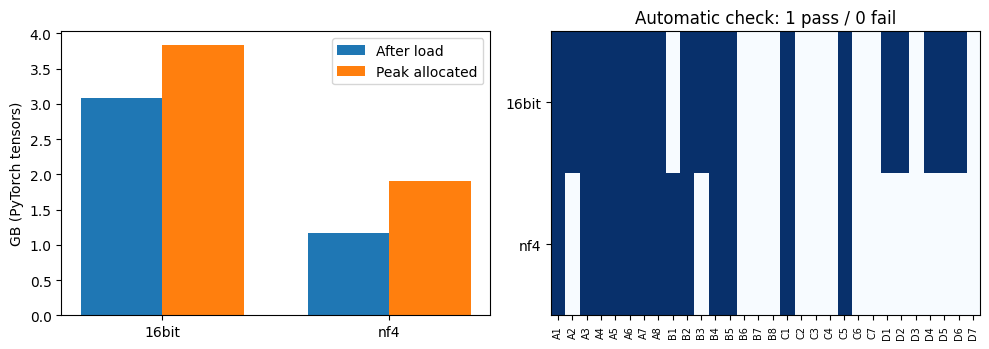

In [22]:
import numpy as np
import matplotlib.pyplot as plt
valid = [(p,r) for p,r in results.items() if "correct" in r]
if valid:
    fig, axes = plt.subplots(1,2,figsize=(10,3.6))
    positions=np.arange(len(valid)); width=.36
    axes[0].bar(positions-width/2,[r.get("weights_gb",np.nan) for p,r in valid],width,label="After load")
    axes[0].bar(positions+width/2,[r.get("peak_gb",np.nan) for p,r in valid],width,label="Peak allocated")
    axes[0].set(xticks=positions,xticklabels=[p for p,r in valid],ylabel="GB (PyTorch tensors)")
    axes[0].legend()
    matrix=np.array([[int(r["correct"][q["id"]]) if q["id"] in r["correct"] else np.nan for q in QUESTIONS] for p,r in valid])
    axes[1].imshow(matrix,aspect="auto",vmin=0,vmax=1,cmap="Blues")
    axes[1].set(yticks=positions,yticklabels=[p for p,r in valid],xticks=range(len(QUESTIONS)),xticklabels=[q["id"] for q in QUESTIONS],title="Automatic check: 1 pass / 0 fail")
    axes[1].tick_params(axis="x",rotation=90,labelsize=7)
    fig.tight_layout();fig.savefig("d54_memory_and_answers.png",dpi=85);plt.show()

**[목표 2] 품질 비교를 짧게 복습합니다.**

메모리 절약률과 초당 토큰 수를 먼저 읽고 정답 수와 맞→틀 문항을 확인합니다. 퍼플렉서티와 토큰 1순위 일치율은 참고 지표로 읽으며 업무 정답을 대신하지 않습니다. 답이 하나도 바뀌지 않았다면 관찰한 질문 범위에서 그렇게 기록합니다.

In [23]:
# 뒤집힌 질문을 직접 읽습니다(16비트 기준선이 있어야 합니다)
b = results.get("16bit", {})
for p in ["int8", "nf4"]:
    r = results.get(p, {})
    if "correct" not in b or "correct" not in r:
        continue
    changed = [q for q in QUESTIONS if b["correct"][q["id"]] != r["correct"][q["id"]]]
    print(f"\n[{p}] 16비트와 맞고 틀림이 달라진 질문 {len(changed)}개")
    for q in changed:
        print(f"  {q['id']} ({q['type']}) 정답 {q['answer']}\n     16bit : {b['answers'][q['id']][:60]!r}"
              f"\n     {p:<5} : {r['answers'][q['id']][:60]!r}")


[nf4] 16비트와 맞고 틀림이 달라진 질문 8개
  A2 (지문) 정답 3
     16bit : '오후 3시'
     nf4   : '17시'
  B1 (계산) 정답 10.5
     16bit : '8.5일'
     nf4   : '남은 연차: 10.5일'
  B3 (계산) 정답 24
     16bit : '24만원'
     nf4   : '28'
  D1 (형식) 정답 {'부서': '인사팀', '날짜': '2026-03-04'}
     16bit : '{\n  "부서": "인사팀",\n  "날짜": "2026-03-04"\n}'
     nf4   : '```json\n{\n  "부서": "인사",\n  "날짜": "2026-03-04"\n}\n```'
  D2 (형식) 정답 {'부서': '보안팀', '날짜': '2026-11-20'}
     16bit : '{\n  "부서": "보안팀",\n  "날짜": "2026-11-20"\n}'
     nf4   : '```json\n{\n  "부서": "보안팀",\n  "날짜": "2026-11-20"\n}\n```'
  D4 (형식) 정답 {'부서': '총무팀', '날짜': '2026-12-01'}
     16bit : '{\n  "부서": "총무팀",\n  "날짜": "2026-12-01"\n}'
     nf4   : '```json\n{\n  "부서": "총무팀",\n  "날짜": "2026-12-01"\n}\n```'
  D5 (형식) 정답 {'부서': '영업팀', '날짜': '2026-10-15'}
     16bit : '{\n  "부서": "영업팀",\n  "날짜": "2026-10-15"\n}'
     nf4   : '```json\n{\n  "부서": "영업팀",\n  "날짜": "2026-10-15"\n}\n```'
  D6 (형식) 정답 {'부서': '개발팀', '날짜': '2026-09-30'}
     16bit : '{\n  "부서": "개발팀",\n  "날짜": 

뒤집힌 질문이 어느 유형(지문, 계산, 분류, 형식)에 몰렸는지 봅니다.

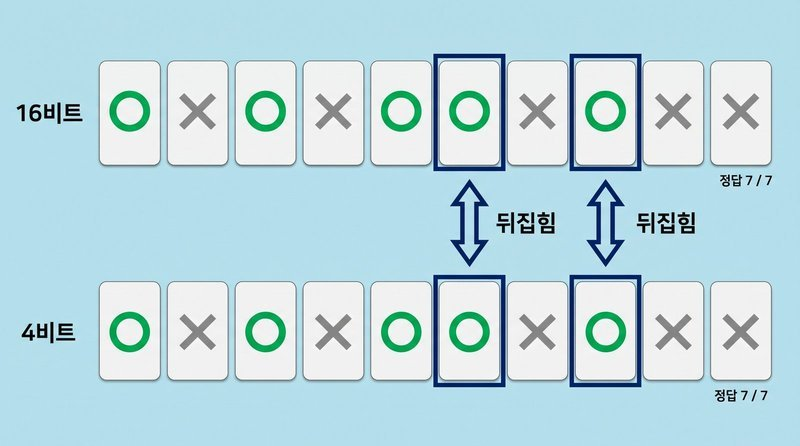

*정답 수가 같아도 일부 문항의 답이 바뀌어(flip) 있습니다.*

### Step 6. 중요 질문 원문 검토와 교체 판단

아래 출력에서 A8·C5의 원본과 NF4 답을 모두 읽습니다. 정오답과 이유를 직접 입력한 다음 판단 함수를 실행합니다. 초기값 `None`은 아직 읽지 않았다는 뜻이며 자동 채점값으로 채우지 않습니다.

원문에서 답을 확인할 수 없으면 미확인으로 남기고 보류합니다. 자동·수동 판정이 다르면 공통 채점기를 혼자 고치지 말고 기준을 먼저 검토합니다.

아래 판단 함수는 제공 코드입니다. 함수를 줄마다 새로 작성하는 과제는 아닙니다. 학습자는 두 질문의 답을 읽고 정오와 이유를 기록한 뒤, 출력된 판단 상태가 자신의 근거와 맞는지 확인합니다.

In [24]:
import math

def review_pair(questions, baseline, candidate, critical_ids, manual, min_saving=.20, max_new_errors=0):
    """실습용 근거 정리 함수입니다. 운영 서비스의 출시 승인 함수가 아닙니다."""
    # 20%는 이 실습의 임시 목표입니다. 실무의 기준값은 아닙니다.
    ids = [q["id"] for q in questions]
    if len(ids) != len(set(ids)) or not ids or not critical_ids or not set(critical_ids) <= set(ids):
        raise ValueError("질문 ID와 중요 질문을 확인합니다.")
    if not 0 <= min_saving < 1 or type(max_new_errors) is not int or max_new_errors < 0:
        raise ValueError("판정 조건을 확인합니다.")
    missing = []
    rows = []
    for q in questions:
        qid = q["id"]
        b = baseline.get("correct", {}).get(qid)
        c = candidate.get("correct", {}).get(qid)
        if type(b) is not bool or type(c) is not bool:
            missing.append(qid)
            transition = "미확인"
        else:
            transition = "맞→틀" if b and not c else "틀→맞" if c and not b else "유지"
        rows.append({"id": qid, "type": q["type"], "baseline": b, "candidate": c,
                     "transition": transition, "critical": qid in critical_ids})
        for result in (baseline, candidate):
            answer = result.get("answers", {}).get(qid)
            if not isinstance(answer, str) or not answer.strip(): missing.append(qid)
    pending, critical_wrong, judge_disagreement = [], [], []
    for qid in critical_ids:
        item = manual.get(qid, {})
        if type(item.get("baseline")) is not bool or type(item.get("candidate")) is not bool or not item.get("reason", "").strip():
            pending.append(qid); continue
        if not item["candidate"]: critical_wrong.append(qid)
        for key, result in [("baseline", baseline), ("candidate", candidate)]:
            if item[key] != result.get("correct", {}).get(qid): judge_disagreement.append(qid+":"+key)
    bmem, cmem = baseline.get("weights_gb"), candidate.get("weights_gb")
    numeric = lambda x: type(x) in (int, float) and math.isfinite(x) and x > 0
    saving = 1-cmem/bmem if numeric(bmem) and numeric(cmem) else None
    new_errors = [r["id"] for r in rows if r["transition"] == "맞→틀"]
    baseline_count = None if missing else sum(baseline["correct"][qid] for qid in ids)
    candidate_count = None if missing else sum(candidate["correct"][qid] for qid in ids)
    # 읽지 못한 결과는 0점으로 바꾸지 않고 근거 부족으로 남깁니다.
    if missing or saving is None or baseline.get("error") or candidate.get("error"):
        decision = "근거 부족"
    elif pending:
        decision = "답 검토 대기"
    elif judge_disagreement:
        decision = "채점 기준 재검토"
    elif critical_wrong or len(new_errors) > max_new_errors or candidate_count < baseline_count or saving < min_saving:
        decision = "교체 보류"
    else:
        decision = "추가 평가 대상"
    return {"decision": decision, "baseline_correct": baseline_count, "candidate_correct": candidate_count,
        "memory_saving": saving, "new_errors": new_errors, "missing": missing, "pending": pending,
        "critical_wrong": critical_wrong, "judge_disagreement": judge_disagreement, "rows": rows,
        "limits": "30개 고정 질문의 실습 결과입니다. 운영 배포 승인이나 통계적 성능 보장이 아닙니다."}


검토 기록의 `baseline`은 원본 답, `candidate`는 NF4 답의 정오 여부입니다. 실제로 읽고 맞으면 `True`, 틀리면 `False`를 적습니다. 판단 이유에는 기대 답과 실제 표현을 연결합니다.

In [25]:
# 실제 출력 원문을 읽고 채웁니다. 자동 채점값을 그대로 옮기지 않습니다.
manual_review = {qid: {"baseline": None, "candidate": None, "reason": ""} for qid in CRITICAL_IDS}

for qid in CRITICAL_IDS:
    q = next(q for q in QUESTIONS if q["id"] == qid)
    print("\n중요 질문:", qid, q["q"], "\n기대 답:", q["answer"])
    for name in ("16bit", "nf4"):
        r = results.get(name, {})
        print(name, "자동 채점:", r.get("correct", {}).get(qid),
              "원문:", r.get("answers", {}).get(qid, "[응답 기록 없음]"))

# 아래에 실제로 읽은 판단을 기록합니다. 두 질문 모두 기준·후보의 정오와 이유를 남깁니다.
# 예시 형식: manual_review["A8"] = {"baseline": True, "candidate": False, "reason": "실제 답을 근거로 작성"}
# 위 예시는 실제 측정 결과가 아니므로 복사해 제출하지 않습니다.


중요 질문: A8 다음 규정을 읽고 답하십시오.
규정 : 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
질문 : 보안 사고를 알게 되면 몇 시간 안에 알려야 합니까? 숫자만 답하십시오. 
기대 답: 1
16bit 자동 채점: True 원문: 1시간
nf4 자동 채점: True 원문: 1시간

중요 질문: C5 다음 문의를 인사, 보안, 재무, 총무 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.
문의 : 고객 명단 파일을 협력사에 메일로 보내도 되나요? 
기대 답: 보안
16bit 자동 채점: True 원문: 보안
nf4 자동 채점: True 원문: 보안


In [26]:
decision = review_pair(QUESTIONS, results.get("16bit", {}), results.get("nf4", {}),
                       CRITICAL_IDS, manual_review, MIN_MEMORY_SAVING, MAX_NEW_ERRORS)
print({k: v for k,v in decision.items() if k != "rows"})
print("자동 채점의 맞→틀:", decision["new_errors"])
print("후보의 중요 질문 오답:", decision["critical_wrong"])
record = {"critical_ids": CRITICAL_IDS, "min_memory_saving": MIN_MEMORY_SAVING,
          "max_new_errors": MAX_NEW_ERRORS, "manual_review": manual_review,
          "measurement_conditions": measurement_conditions(MODEL_ID, DTYPE16), "review": decision}
with open("d54_decision.json", "w", encoding="utf-8") as f:
    json.dump(record, f, ensure_ascii=False, indent=2)
print("저장: d54_decision.json. 검토 대기 상태도 그대로 남깁니다.")

{'decision': '답 검토 대기', 'baseline_correct': 19, 'candidate_correct': 13, 'memory_saving': 0.6232711832701617, 'new_errors': ['A2', 'B3', 'D1', 'D2', 'D4', 'D5', 'D6'], 'missing': [], 'pending': ['A8', 'C5'], 'critical_wrong': [], 'judge_disagreement': [], 'limits': '30개 고정 질문의 실습 결과입니다. 운영 배포 승인이나 통계적 성능 보장이 아닙니다.'}
자동 채점의 맞→틀: ['A2', 'B3', 'D1', 'D2', 'D4', 'D5', 'D6']
후보의 중요 질문 오답: []
저장: d54_decision.json. 검토 대기 상태도 그대로 남깁니다.


**[목표 3] 상태와 근거를 읽습니다.**

검토 전에는 “답 검토 대기”가 나오는 것이 정상입니다. 검토 뒤에도 중요 질문 오답·신규 오답·채점기 오판이 있으면 해당 근거를 남깁니다. “추가 평가 대상”이 나와도 이번 30개 문항을 통과한 범위에서만 말합니다.

### Step 7. 선택 비교: int8 한 행 추가

필수 검토를 마쳤고 시간이 남는 경우에만 실행합니다. 같은 모델의 int8을 추가해 D38의 세 정밀도 비교를 복습합니다. 이 셀을 실행하지 않아도 D55\~57에서 필요한 기준선·NF4 결과는 남습니다.

In [27]:
RUN_OPTIONAL_INT8 = False  # 필수 수행을 마친 뒤 선택할 때만 True로 바꿉니다.
if RUN_OPTIONAL_INT8:
    h = load_model(MODEL_ID, "int8")
    try:
        results["int8"] = {"precision": "int8", "error": h["error"]} if "error" in h else measure_all(h)
    finally:
        if "error" not in h: unload(h)
    print("int8 추가 결과:", {k:v for k,v in results["int8"].items() if k not in ("preds", "answers")})
    print("추가 결과를 보관하려면 Step 5의 표·저장 셀만 다시 실행합니다. 모델 측정 셀 전체는 다시 실행하지 않습니다.")
else:
    print("선택 int8을 건너뜁니다. 결과 파일에 int8 행이 없어도 정상입니다.")

선택 int8을 건너뜁니다. 결과 파일에 int8 행이 없어도 정상입니다.


### Step 8. 근거 공유와 파일 인계

중요 질문의 실제 답, 자동·수동 채점의 차이, 교체 판단과 다시 확인할 조건을 짝과 비교합니다. 추가 GPU 측정을 늘리기 전에 이미 얻은 결과를 해석합니다.

| 다음 수업 | 오늘 넘기는 것 | 이어서 확인할 것 |
|---|---|---|
| D55 프루닝·증류 | 공통 하네스·원본/NF4 결과 | 같은 조건에서 실제로 줄어든 자원 |
| D56 GPTQ·AWQ | 공통 질문·채점·조건 기록 | 보정 입력·파일 제작 후 재평가 |
| D57 vLLM | 공통 질문과 생성 설정 | 서버 실행·동시 요청의 운영 성능 |

세 파일을 내려받아 보관합니다. 실행 창을 닫기 전에 아래의 파일 검사 셀을 실행합니다.

In [28]:
from pathlib import Path
required = ["bench_harness.py", "d54_results.json", "d54_decision.json"]
for name in required:
    p = Path(name)
    if not p.is_file(): raise FileNotFoundError("먼저 실행할 단계가 있습니다: "+name)
    print(name, p.stat().st_size, "bytes")
payload = json.loads(Path("d54_results.json").read_text(encoding="utf-8"))
print("다음 차시에 넘길 기준 조건:", payload.get("_conditions"))
print("측정 행:", [k for k in payload if not k.startswith("_")])
print("세 파일을 코랩 파일 창에서 내려받아 보관합니다. D55는 하네스·결과 파일을 사용합니다.")
print("코랩 왼쪽 파일 아이콘에서 파일별 메뉴의 다운로드를 선택합니다. D55에서 파일 업로드로 /content에 다시 올립니다.")
print("필수 측정은 16bit·NF4입니다. int8 키가 없어도 정상입니다.")
print("D56~57의 팀 RunPod에는 하네스·결과 파일을 /workspace 아래에 업로드합니다.")

bench_harness.py 23617 bytes
d54_results.json 4793 bytes
d54_decision.json 6740 bytes
다음 차시에 넘길 기준 조건: {'model': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306', 'dtype16': 'torch.float16', 'gpu': 'Tesla T4', 'questions': 30, 'questions_sha256': '1bbef818266665fbf9fb0235b071483dd2ec5a2063c870b21838bc74a329a8fd', 'generation_sha256': 'e70262b98d0ac915fe608e7092ae425000e6ed3ca39dab41d39a01ecb0516b4c', 'harness_sha256': '9aa1d57ef3ddf1fef641ee019f81889c1935e5dc05530958605a309b771f7f27', 'versions': {'torch': '2.11.0+cu130', 'transformers': '5.22.0', 'accelerate': '1.15.0', 'bitsandbytes': '0.50.2'}}
측정 행: ['16bit', 'nf4']
세 파일을 코랩 파일 창에서 내려받아 보관합니다. D55는 하네스·결과 파일을 사용합니다.
코랩 왼쪽 파일 아이콘에서 파일별 메뉴의 다운로드를 선택합니다. D55에서 파일 업로드로 /content에 다시 올립니다.
필수 측정은 16bit·NF4입니다. int8 키가 없어도 정상입니다.
D56~57의 팀 RunPod에는 하네스·결과 파일을 /workspace 아래에 업로드합니다.


### 혼자 설명하기

4비트 모델의 메모리가 줄고 전체 정답 수가 같았습니다. 미리 정한 중요 질문 두 개의 실제 답과 자동 채점을 대조해 교체 판단을 설명합니다. 바뀐 답이 없다면 검토한 답과 측정 조건을 근거로, 추가로 확인할 범위를 적습니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 오차의 원인 | 그룹별 오차 그림과 두 입력의 출력 오차 |
| [목표 2] 채점과 실제 답 | 원본·후보의 원문 두 쌍, 자동·수동 판단과 이유 |
| [목표 3] 교체 판단과 인계 | 판단 상태, 측정 조건, 다음 차시에 쓸 파일 |

D55에서는 같은 하네스로 프루닝·증류 결과를 비교합니다. D56에서는 오늘 확인한 입력·그룹·오차의 관계를 바탕으로 GPTQ·AWQ 파일을 만들고 다시 평가합니다.

### 마무리 과제. 양자화 판단서

아래 다섯 칸으로 판단서를 씁니다. 선택 int8을 수행하지 않았다면 원본·NF4 두 행으로 작성합니다.

| 칸 | 남길 내용 | 연결 목표 |
|---|---|---|
| 오차 설명 | 그룹·입력 변경 전후의 그림과 출력 오차 | 목표 1 |
| 비교 조건 | GPU·모델 버전·계산 형식·생성 설정·질문 | 목표 2 |
| 품질 리마인드 | 원본·NF4의 메모리·속도·정답과 신규 오답 | 목표 2 |
| 직접 읽은 답 | A8·C5 원문 쌍, 자동·수동 정오와 이유 | 목표 2·3 |
| 판단과 인계 | 판단 상태·추가 확인 범위·세 파일 | 목표 3 |

정답 수가 같아도 문항별 변화가 있는지 확인합니다. 중요 질문에서 원본도 틀렸다면 원본이 신뢰할 만한 업무 기준인지부터 다시 검토합니다. 바뀐 답이 없거나 교체를 보류한 결과도 근거가 있으면 완료로 인정합니다.